In [2]:
import pandas as pd
from upsetplot import from_indicators, UpSet
import matplotlib.pyplot as plt
from itertools import combinations

In [5]:
df = pd.read_csv('../general_analyses/count_peptides/proteomics_detected_orfs_with_extra_features.csv')
df.columns

Index(['protein', '1_peptides', '1_peptides_no_match_sp', '2_peptides',
       '2_peptides_no_match_sp', '3_peptides_proteotypic',
       '3_peptides_not_proteotypic', '4_peptides', '4_peptides_no_match_sp',
       'orf_id', 'ORF_ranges', 'Protein', 'gene_id', 'gene_biotype',
       'gene_name', 'transcript_id', 'uniprot_gn_ids', 'cl_mean', 'ps_mean',
       'ps_n_translated', 'ps_translated', 'translated_A673',
       'translated_SKNMC', 'translated_MHHES1', 'translated_RDES',
       'translated_TC106', 'EwS_specific', 'orf_category_new',
       'same_as_orfquant', 'same_as_orfquant_start', 'neotranscript_orf_type',
       'neotranscript_type', 'isoform_final', 'distance_chip', 'distance_msat',
       'peak_orth_near', 'ggaa_near', 'Peptides_SB', 'Number_SB',
       'Peptides_WB', 'Number_WB', 'class', 'any_peptide_found_in_IP',
       'result_A673', 'result_SKNMC', 'result_MHHES', 'result_TC106',
       'result_RDES', 'detected_in_hla_la', 'hla_la_peptide',
       'n_downregulated', 

In [6]:
df['detected_tr'] = df['1_peptides'].notna()|df['1_peptides_no_match_sp'].notna()
df['detected_MSK'] = df['2_peptides'].notna()|df['2_peptides_no_match_sp'].notna()
df['detected_DKFZ'] = df['3_peptides_proteotypic'].notna()|df['3_peptides_not_proteotypic'].notna()
df['detected_ip'] = df['4_peptides'].notna()|df['4_peptides_no_match_sp'].notna()

In [7]:
df['orf_cathegoty_toplot'] = df['neotranscript_orf_type'].where(df['neotranscript_orf_type'] != 'Non-canonical ORF general', df['orf_category_new'])
df = df[df['orf_cathegoty_toplot']!='ORF_variant']

In [8]:
df = df[['orf_id', 'detected_ip', 'detected_MSK',  'detected_tr','detected_DKFZ' ]]

In [9]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42        # ← renders text as text in Illustrator (Type 1 → TrueType)
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'Arial'    # ← Arial font


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.


detected_ip  detected_MSK  detected_tr  detected_DKFZ
True         False         False        False            691
False        True          False        False            148
             False         True         False             92
                           False        True              44
True         True          False        False             63
             False         True         False             56
                           False        True              18
False        True          True         False             84
                           False        True              26
             False         True         True              23
True         True          True         False             54
                           False        True              15
             False         True         True              15
False        True          True         True              22
True         True          True         True              15
dtype: int64


/home/mariia/miniforge3/envs/analysis/lib/python3.14/site-packages/upsetplot/plotting.py:795: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  styles["linewidth"].fillna(1, inplace=True)
/home/mariia/miniforge3/envs/analysis/lib/python3.14/site-packages/upsetplot/plotting.py:796: ChainedAssignmentError: A value is being set on a copy of

ValueError: Invalid RGBA argument: nan

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

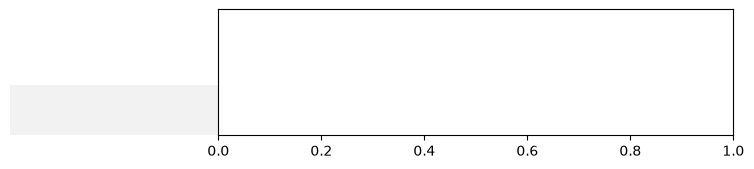

In [10]:
set_cols = ['detected_ip', 'detected_MSK',  'detected_tr','detected_DKFZ']
bool_df = df[set_cols].astype(bool)

# For inclusive intersections: for each possible combo of sets,
# count elements that are in ALL sets of that combo (regardless of other memberships)
index_tuples = []
counts = []

for r in range(1, len(set_cols) + 1):
    for combo in combinations(set_cols, r):
        # element must be True in every set in this combo
        mask = bool_df[list(combo)].all(axis=1)
        count = mask.sum()
        # MultiIndex tuple: True only for sets IN this combo
        index_tuples.append(tuple(col in combo for col in set_cols))
        counts.append(count)

index = pd.MultiIndex.from_tuples(index_tuples, names=set_cols)
data = pd.Series(counts, index=index)

print(data)  # sanity check before plotting

fig = plt.figure(figsize=(10, 5))
UpSet(data, subset_size='sum', sort_by='cardinality', show_counts=True).plot(fig)
plt.tight_layout()
plt.savefig('upset_plot.pdf',  dpi=300, bbox_inches='tight')
plt.show()